# NQ Price Distributions — Standard-Deviation Bands From The Open

End-to-end recreation of the nqstats.com/price_distributions study, run against
15 years of NQ 1-minute data.

**Method.** For each period (hour / session / day / week), measure the net return
from the open, `r = (close − open) / open`. Take `σ(r)` over a lookback, then draw
bands at `open × (1 ± k·σ)`. Each band maps to a probability via the normal CDF.

**What this notebook adds.** The 38% / 68% / 87% figures quoted on the site are the
textbook normal values `2Φ(k) − 1` — you get them without looking at a single NQ
bar. Index futures aren't normal, so every table here shows the *empirical* rate
beside the theoretical one. It also uses walk-forward σ (no look-ahead), separates
*touching* a band from *closing* outside it, and fits σ per hour-of-day.

Run top to bottom. Only the `FILE_PATH` in the next cell needs editing.

In [1]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

# This notebook is written to run on pandas 1.3+, 2.x and 3.x. If anything below
# raises a TypeError about an unexpected keyword, check these versions first.
print(f"pandas {pd.__version__} | numpy {np.__version__} | scipy {__import__('scipy').__version__}")

# ── CONFIG ────────────────────────────────────────────────────────────────────
FILE_PATH  = "/mnt/user-data/uploads/nq_15y_1min__1_.csv"   # ← your 1-min CSV
CACHE_PATH = "nq_minute_cache.pkl"    # parsed bars cached here; delete to re-parse
OUTDIR     = "dist_output"

START_DATE = None          # e.g. "2015-01-01" to restrict the sample
END_DATE   = None

# Trading-session date convention. 6 = CME standard (Sunday 18:00 open belongs to
# Monday). Your magic_hours notebook effectively uses -18; pass that to match it.
DAY_SHIFT_HOURS = 6

# Sigma model — all estimators are shifted one period, so no look-ahead.
SIGMA_METHOD = "rolling"   # "rolling" | "ewma" | "expanding" | "full"
SIGMA_WINDOW = 252         # periods, for "rolling"
SIGMA_HALFLIFE = 60        # periods, for "ewma"
SIGMA_MIN_PERIODS = 60
SIGMA_CENTER = "zero"      # "zero" = dispersion around the OPEN (matches the bands)
SIGMA_BY_BUCKET = True     # fit σ separately per hour-of-day / session

# Band multiples to evaluate. The site quotes 0.5 / 1.0 / 1.5.
K_GRID = (0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 2.5, 3.0)

# Percentiles for the empirical distribution tables.
QUANTILES = (0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99)
EXT_QUANTILES = (0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99)

# Periods to analyse in the batch run at the end.
PERIODS = ["rth", "day", "week", "hour", "asia", "london"]

os.makedirs(OUTDIR, exist_ok=True)
print("config set")

pandas 1.4.4 | numpy 1.21.5 | scipy 1.9.1
config set


## 1. Load the minute bars

Expects `Date, Time, Open, High, Low, Close` in NY time. Parsing 5M rows takes
~40s, so the result is cached to a pickle — later runs load in a second.

`session_date` rolls the evening Globex open into the next calendar day, which is
what makes "day" and "week" periods line up with how the contract actually trades.

In [2]:
def load_minute_data(file_path, start_date=None, end_date=None, day_shift_hours=6):
    """Load 1-minute bars and attach session-date columns."""
    head = pd.read_csv(file_path, nrows=0)
    cols_lower = {c.lower(): c for c in head.columns}
    wanted = [cols_lower[c] for c in
              ("date", "time", "datetime", "timestamp", "open", "high", "low", "close")
              if c in cols_lower]
    df = pd.read_csv(
        file_path, usecols=wanted,
        dtype={cols_lower[c]: "float64"
               for c in ("open", "high", "low", "close") if c in cols_lower},
    )

    # Parsing Date and Time separately lets pandas cache repeated values — far
    # lighter than building 5M concatenated strings.
    if "date" in cols_lower and "time" in cols_lower:
        dates = pd.to_datetime(df.pop(cols_lower["date"]), format="%Y-%m-%d", cache=True)
        dt = dates + pd.to_timedelta(df.pop(cols_lower["time"]))
        del dates
    elif "datetime" in cols_lower:
        dt = pd.to_datetime(df.pop(cols_lower["datetime"]))
    elif "timestamp" in cols_lower:
        dt = pd.to_datetime(df.pop(cols_lower["timestamp"]))
    else:
        raise ValueError(f"No datetime columns found in {list(head.columns)}")

    df = df.rename(columns={cols_lower[s]: s.capitalize()
                            for s in ("open", "high", "low", "close") if s in cols_lower})
    df = df.assign(Datetime=dt).set_index("Datetime").sort_index()
    df = df[["Open", "High", "Low", "Close"]]

    if start_date:
        df = df.loc[pd.Timestamp(start_date):]
    if end_date:
        df = df.loc[:pd.Timestamp(end_date)]

    df = df[~df.index.duplicated(keep="first")].dropna()

    df["session_date"] = (df.index + pd.Timedelta(hours=day_shift_hours)).normalize()
    df["hour"] = df.index.hour
    df["tod"] = df.index.hour * 60 + df.index.minute   # minutes since midnight
    df["dow"] = df["session_date"].dt.dayofweek

    print(f"Loaded {len(df):,} bars  |  {df.index[0]:%Y-%m-%d %H:%M} -> "
          f"{df.index[-1]:%Y-%m-%d %H:%M}  |  {df['session_date'].nunique():,} sessions")
    return df


if os.path.exists(CACHE_PATH):
    df = pd.read_pickle(CACHE_PATH)
    print(f"Loaded from cache: {len(df):,} bars  "
          f"({df.index[0]:%Y-%m-%d} -> {df.index[-1]:%Y-%m-%d})")
else:
    df = load_minute_data(FILE_PATH, START_DATE, END_DATE, DAY_SHIFT_HOURS)
    df.to_pickle(CACHE_PATH)

df.head(3)

Loaded from cache: 4,974,698 bars  (2010-06-06 -> 2025-03-14)


,Open,High,Low,Close,session_date,hour,tod,dow
Datetime,,,,,,,,
2010-06-06 20:00:00,1826.25,1826.5,1826.00,1826.50,2010-06-07,20,1200,0
2010-06-06 20:01:00,1826.50,1826.5,1826.50,1826.50,2010-06-07,20,1201,0
2010-06-06 20:02:00,1826.50,1826.5,1825.75,1825.75,2010-06-07,20,1202,0


### Sanity check the session clock

The maintenance break should show up as a near-empty hour. On CME NY time that's
17:00–18:00. If the gap sits somewhere else, your data is in a different timezone
and every session window below needs shifting.

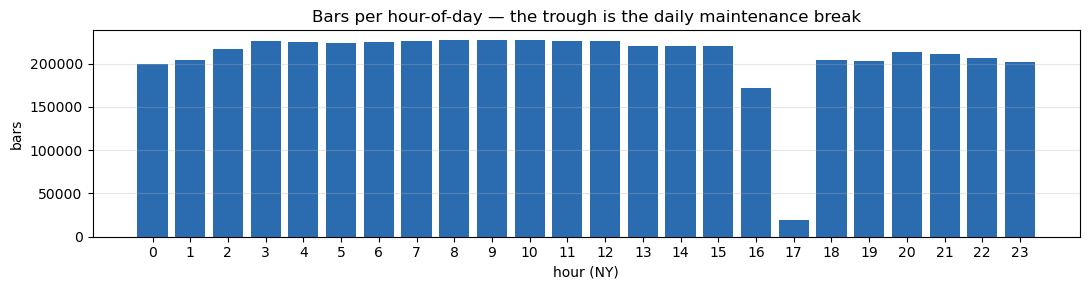

Quietest hour: 17:00 (19,557 bars vs 220,376 median)


In [3]:
bars_by_hour = df.groupby("hour").size()
fig, ax = plt.subplots(figsize=(11, 3))
ax.bar(bars_by_hour.index, bars_by_hour.values, color="#2b6cb0")
ax.set_title("Bars per hour-of-day — the trough is the daily maintenance break")
ax.set_xlabel("hour (NY)"); ax.set_ylabel("bars"); ax.set_xticks(range(24))
ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

print(f"Quietest hour: {bars_by_hour.idxmin():02d}:00 "
      f"({bars_by_hour.min():,} bars vs {int(bars_by_hour.median()):,} median)")

### Data quality — price-scale anomalies

Long histories stitched from multiple vendors sometimes carry blocks where prices
are off by a factor of 10 or 100. Comparing each session's median price to a
21-session rolling median finds them.

These are mostly harmless *here* — every statistic in this notebook is a ratio
within a single period, so a uniformly rescaled block still yields correct returns
provided the switch happens at a session boundary. They do wreck any point-based
output, though, and the check below reports whether the switch is clean.

In [4]:
def find_scale_anomalies(d, window=21, tol=3.0):
    med = d.groupby("session_date")["Close"].median()
    ref = med.rolling(window, center=True, min_periods=5).median()
    ratio = med / ref
    return ratio[(ratio > tol) | (ratio < 1 / tol)]


def repair_scale_anomalies(d, anomalies):
    """Divide flagged sessions by the nearest power of ten."""
    if not len(anomalies):
        return d
    d = d.copy()
    for sd, r in anomalies.items():
        factor = 10 ** round(np.log10(r))
        m = d["session_date"] == sd
        d.loc[m, ["Open", "High", "Low", "Close"]] /= factor
    return d


anom = find_scale_anomalies(df)
if len(anom):
    print(f"{len(anom)} session(s) flagged as mis-scaled:\n")
    for sd, r in anom.items():
        print(f"  {sd:%Y-%m-%d}   level ×{r:,.1f}  ->  nearest power of ten: "
              f"×{10 ** round(np.log10(r)):,.0f}")

    # Does the scale switch land on a session boundary? If so, within-period
    # returns are untouched and nothing below is contaminated.
    jumps = df["Close"].pct_change().abs()
    breaks = jumps[jumps > 0.5]
    clean = all(t.hour == 18 and t.minute == 0 for t in breaks.index)
    verdict = ("all at the 18:00 session open — within-period returns are unaffected"
               if clean else
               "NOT all at session boundaries — returns ARE contaminated")
    print(f"\n  {len(breaks)} minute-level scale breaks, {verdict}")

    if not clean:
        df = repair_scale_anomalies(df, anom)
        print("  -> repaired by rescaling the affected sessions")
else:
    print("No price-scale anomalies found.")

5 session(s) flagged as mis-scaled:

  2012-02-06   level ×98.6  ->  nearest power of ten: ×100
  2012-02-07   level ×98.6  ->  nearest power of ten: ×100
  2012-02-08   level ×98.8  ->  nearest power of ten: ×100
  2012-02-09   level ×98.5  ->  nearest power of ten: ×100
  2012-02-10   level ×98.6  ->  nearest power of ten: ×100

  2 minute-level scale breaks, all at the 18:00 session open — within-period returns are unaffected


## 2. Aggregate minute bars into periods

`period` accepts `"hour"`, `"day"`, `"week"`, a named session, or any custom
`"HH:MM-HH:MM"` window. Periods with fewer than half the median bar count are
dropped — that clears holidays, half-days and data gaps that would otherwise
inflate σ.

In [5]:
SESSION_WINDOWS = {
    "globex": ("18:00", "17:00"),   # full electronic day
    "asia":   ("18:00", "03:00"),
    "london": ("03:00", "09:30"),
    "rth":    ("09:30", "16:00"),   # NY regular trading hours
    "nyam":   ("09:30", "12:00"),
    "nypm":   ("12:00", "16:00"),
    # Windows matching the "Session Statistical Levels" Pine indicator, so the
    # exported levels line up with what it plots. Note these differ from the
    # ones above — its NY morning starts pre-market at 08:00, not at the RTH open.
    "pine_asia":   ("19:00", "02:00"),
    "pine_london": ("02:00", "08:00"),
    "pine_nyam":   ("08:00", "12:00"),
    "pine_nypm":   ("12:00", "17:00"),
}


def _tod_minutes(hhmm):
    h, m = hhmm.split(":")
    return int(h) * 60 + int(m)


def _session_mask(d, start, end):
    """Bars inside [start, end), handling the midnight wrap."""
    s, e = _tod_minutes(start), _tod_minutes(end)
    return (d["tod"] >= s) & (d["tod"] < e) if s < e else (d["tod"] >= s) | (d["tod"] < e)


def _agg(grp):
    return pd.DataFrame({
        "Open": grp["Open"].first(), "High": grp["High"].max(),
        "Low": grp["Low"].min(), "Close": grp["Close"].last(),
        "bars": grp["Close"].size(),
    })


def _period_key(d, period):
    """
    Resolve a period spec into (mask, key, expected_bars).

    Factored out so that the bar-by-bar path tracker in section 10 groups minute
    bars exactly the way build_periods does — one definition, no drift.
    """
    if period == "hour":
        return (pd.Series(True, index=d.index),
                pd.Series(d.index.floor("60min"), index=d.index), 60)

    if period in ("day", "week"):
        mask = _session_mask(d, *SESSION_WINDOWS["globex"])
        sd = d["session_date"]
        key = sd if period == "day" else (
            sd - pd.to_timedelta(sd.dt.dayofweek, unit="D"))
        return mask, key, None

    if period in SESSION_WINDOWS:
        start, end = SESSION_WINDOWS[period]
    elif "-" in period:
        start, end = period.split("-")
    else:
        raise ValueError(f"Unknown period spec: {period!r}")

    s, e = _tod_minutes(start), _tod_minutes(end)
    expected = (e - s) if e > s else (1440 - s + e)
    return _session_mask(d, start, end), d["session_date"], expected


def build_periods(d, period="rth", min_bar_frac=0.5, verbose=True):
    """Aggregate minute bars into period OHLC with a conditioning `bucket`."""
    mask, key, expected = _period_key(d, period)
    sub = d[mask]
    grp = sub.groupby(key[mask])
    out = _agg(grp)

    if period == "hour":
        out["session_date"] = grp["session_date"].first()
        out["bucket"] = out.index.hour.astype(str).str.zfill(2) + ":00"
    else:
        out["session_date"] = out.index
        out["bucket"] = period

    ref = out["bars"].median() if expected is None else min(expected, out["bars"].median())
    min_bars = int(ref * min_bar_frac)
    n0 = len(out)
    out = out[(out["bars"] >= min_bars) & (out["session_date"].dt.dayofweek < 5)]
    out = out.dropna(subset=["Open", "High", "Low", "Close"])
    out = out[out["Open"] > 0]

    if verbose:
        print(f"  period={period:<12} {len(out):>7,} periods  "
              f"(dropped {n0 - len(out):,} thin/weekend, min_bars={min_bars})")
    return out


def add_returns(periods):
    """Net return from the open, plus the intraperiod excursions."""
    out = periods.copy()
    o = out["Open"]
    out["ret"] = (out["Close"] - o) / o     # what the bands model
    out["up_exc"] = (out["High"] - o) / o   # how far above the open it reached
    out["dn_exc"] = (o - out["Low"]) / o
    out["range_pct"] = (out["High"] - out["Low"]) / o
    return out


rth = add_returns(build_periods(df, "rth"))
rth[["Open", "High", "Low", "Close", "bars", "ret"]].tail(3)

  period=rth            3,771 periods  (dropped 18 thin/weekend, min_bars=195)


,Open,High,Low,Close,bars,ret
session_date,,,,,,
2025-03-12,19696.5,19777.75,19395.25,19609.00,390,-0.004442
2025-03-13,19574.0,19577.00,19170.00,19251.50,390,-0.016476
2025-03-14,19465.0,19742.50,19436.75,19705.25,390,0.012343


### Why percent and not points

NQ traded near 2,000 in 2010 and above 21,000 in 2025, so a 50-point move means
something completely different at each end. Every measure in this notebook is
therefore a ratio to the period's own open — `(close − open) / open` — reported in
percent, which makes 2010 and 2025 directly comparable.

Percent is far more stable than points, but it isn't perfectly stationary either:
volatility regimes still shift underneath it. That's what the walk-forward σ in
section 3 is for — dividing by a trailing σ removes the remaining drift, which is
why the σ-unit columns are the ones to compare across eras.

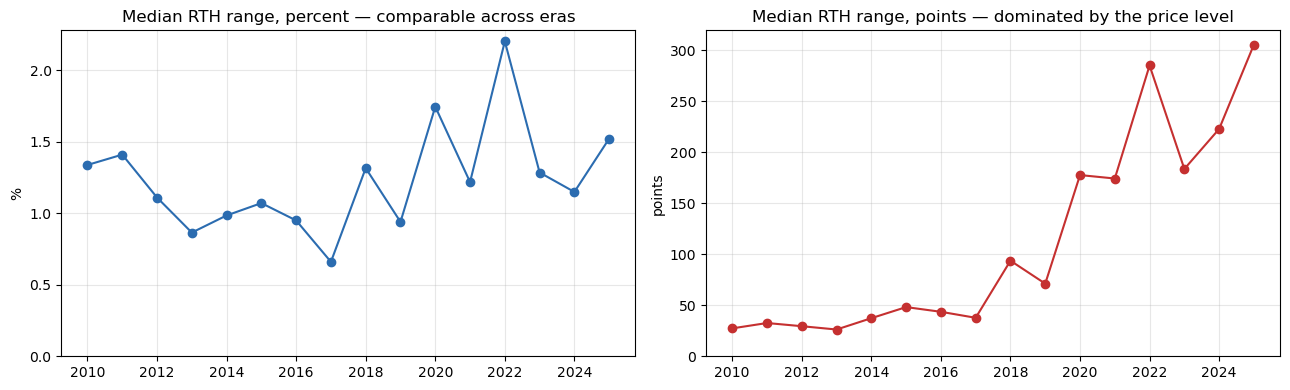

Spread between the loudest and quietest year:
  in percent:  3.2×
  in points:   11.6×


,sessions,mean_price,sigma_%,median_range_%,median_range_PTS
year,,,,,
2010,144,1983.163,0.921,1.337,27.375
2011,252,2291.473,1.119,1.409,32.625
2012,249,7674.577,0.804,1.109,29.500
2013,252,3042.928,0.619,0.864,26.250
2014,248,3846.309,0.753,0.984,37.375
2015,257,4432.850,0.865,1.070,48.250
2016,258,4561.241,0.794,0.949,43.625
2017,256,5759.846,0.534,0.660,37.750
2018,257,7003.087,1.267,1.315,93.750


In [6]:
_p = add_returns(build_periods(df, "rth", verbose=False))
_p["year"] = _p.index.year
_p["range_pts"] = _p["range_pct"] * _p["Open"]      # same range, in points
_g = _p.groupby("year")
stationarity = pd.DataFrame({
    "sessions": _g.size(),
    "mean_price": _g["Open"].mean(),
    "sigma_%": _g["ret"].apply(lambda s: np.sqrt((s ** 2).mean())) * 100,
    "median_range_%": _g["range_pct"].median() * 100,
    "median_range_PTS": _g["range_pts"].median(),
})

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.plot(stationarity.index, stationarity["median_range_%"], marker="o",
        color="#2b6cb0")
ax.set_title("Median RTH range, percent — comparable across eras")
ax.set_ylabel("%"); ax.grid(alpha=0.3); ax.set_ylim(bottom=0)
ax = axes[1]
ax.plot(stationarity.index, stationarity["median_range_PTS"], marker="o",
        color="#c53030")
ax.set_title("Median RTH range, points — dominated by the price level")
ax.set_ylabel("points"); ax.grid(alpha=0.3); ax.set_ylim(bottom=0)
plt.tight_layout(); plt.show()

print(f"Spread between the loudest and quietest year:")
print(f"  in percent:  {stationarity['sigma_%'].max() / stationarity['sigma_%'].min():.1f}×")
print(f"  in points:   {stationarity['median_range_PTS'].max() / stationarity['median_range_PTS'].min():.1f}×")
stationarity.round(3)

## 3. Estimate σ — walk-forward, no look-ahead

Every estimator is shifted one period, so σ for a given session uses only data
that existed *before* it opened. A single full-sample σ — the natural reading of
"collecting these returns across thousands of periods" — peeks at the future and
flatters the coverage. `method="full"` is kept for reference.

`center="zero"` measures dispersion around the **open** (`√mean(r²)`) rather than
around the sample mean, because that's where the bands are actually centred.

In [7]:
def add_sigma(periods, method=SIGMA_METHOD, window=SIGMA_WINDOW,
              halflife=SIGMA_HALFLIFE, min_periods=SIGMA_MIN_PERIODS,
              center=SIGMA_CENTER, by_bucket=SIGMA_BY_BUCKET):
    out = periods.copy()

    def _est(s):
        if center == "zero":
            sq = s.pow(2)
            if method == "rolling":
                v = sq.rolling(window, min_periods=min_periods).mean()
            elif method == "ewma":
                v = sq.ewm(halflife=halflife, min_periods=min_periods).mean()
            elif method == "expanding":
                v = sq.expanding(min_periods=min_periods).mean()
            elif method == "full":
                return pd.Series(np.sqrt(sq.mean()), index=s.index)
            else:
                raise ValueError(method)
            return np.sqrt(v).shift(1)

        if method == "rolling":
            v = s.rolling(window, min_periods=min_periods).std(ddof=1)
        elif method == "ewma":
            v = s.ewm(halflife=halflife, min_periods=min_periods).std(bias=False)
        elif method == "expanding":
            v = s.expanding(min_periods=min_periods).std(ddof=1)
        elif method == "full":
            return pd.Series(s.std(ddof=1), index=s.index)
        else:
            raise ValueError(method)
        return v.shift(1)

    if by_bucket and out["bucket"].nunique() > 1:
        out["sigma"] = out.groupby("bucket", group_keys=False)["ret"].apply(_est)
    else:
        out["sigma"] = _est(out["ret"])
    return out


def add_zscores(periods):
    """Standardise the return and both excursions by the walk-forward σ."""
    out = periods[periods["sigma"].notna() & (periods["sigma"] > 0)].copy()
    out["z"] = out["ret"] / out["sigma"]
    out["z_up"] = out["up_exc"] / out["sigma"]
    out["z_dn"] = out["dn_exc"] / out["sigma"]
    return out


rth = add_zscores(add_sigma(rth))
print(f"{len(rth):,} sessions with a usable σ  "
      f"(first {SIGMA_MIN_PERIODS} consumed by warm-up)")
rth[["Close", "ret", "sigma", "z", "z_up", "z_dn"]].tail(3)

3,711 sessions with a usable σ  (first 60 consumed by warm-up)


,Close,ret,sigma,z,z_up,z_dn
session_date,,,,,,
2025-03-12,19609.00,-0.004442,0.009636,-0.461005,0.428076,1.587174
2025-03-13,19251.50,-0.016476,0.009630,-1.710829,0.015915,2.143177
2025-03-14,19705.25,0.012343,0.009669,1.276491,1.474407,0.150097


## 4. Analysis functions

In [8]:
def coverage_table(periods, k_grid=K_GRID):
    """
    For each band multiple k:
      close_within    P(|z| < k)  — two-sided, "closed inside the band"
      norm_within     2Φ(k) − 1   — normal theory (what the site quotes)
      within_edge     empirical − theory; negative means fatter tails than normal
      close_below_up  P(z < k)    — one-sided
      touch_*         P(the high/low tagged the band intraperiod)
    """
    z, zu, zd = periods["z"], periods["z_up"], periods["z_dn"]
    rows = []
    for k in k_grid:
        within = float((z.abs() < k).mean())
        rows.append({
            "k": k, "n": len(z),
            "close_within": within,
            "norm_within": 2 * stats.norm.cdf(k) - 1,
            "within_edge": within - (2 * stats.norm.cdf(k) - 1),
            "close_below_up": float((z < k).mean()),
            "norm_below": stats.norm.cdf(k),
            "touch_up": float((zu >= k).mean()),
            "touch_dn": float((zd >= k).mean()),
            "touch_either": float(((zu >= k) | (zd >= k)).mean()),
        })
    return pd.DataFrame(rows).set_index("k")


def fade_table(periods, k_grid=K_GRID):
    """
    Mean reversion conditional on a band being tagged. Among periods whose high
    reached the +k band (and symmetrically for the low):
      p_close_inside   closed back inside the band
      p_fade_halfway   retraced at least to the k/2 band
      p_fade_to_open   closed all the way through the open
    """
    rows = []
    for k in k_grid:
        up, dn = periods[periods["z_up"] >= k], periods[periods["z_dn"] >= k]
        n = len(up) + len(dn)
        if n == 0:
            continue
        rows.append({
            "k": k, "n_tagged": n, "tag_rate": n / (2 * len(periods)),
            "p_close_inside": ((up["z"] < k).sum() + (dn["z"] > -k).sum()) / n,
            "p_fade_halfway": ((up["z"] < k / 2).sum() + (dn["z"] > -k / 2).sum()) / n,
            "p_fade_to_open": ((up["z"] < 0).sum() + (dn["z"] > 0).sum()) / n,
        })
    return pd.DataFrame(rows).set_index("k")


def sigma_profile(periods):
    """Realised dispersion by bucket — how σ moves across the clock."""
    g = periods.groupby("bucket")
    return pd.DataFrame({
        "n": g["ret"].size(),
        "sigma_pct": g["ret"].apply(lambda s: np.sqrt((s ** 2).mean())) * 100,
        "mean_ret_pct": g["ret"].mean() * 100,
        "mean_range_pct": g["range_pct"].mean() * 100,
        "kurtosis": g["ret"].apply(lambda s: stats.kurtosis(s.dropna())),
        "skew": g["ret"].apply(lambda s: stats.skew(s.dropna())),
    }).sort_index()


def distribution_summary(periods):
    """Shape diagnostics for the standardised return distribution."""
    z = periods["z"].dropna()
    return {
        "n": int(len(z)), "mean_z": float(z.mean()), "std_z": float(z.std(ddof=1)),
        "skew": float(stats.skew(z)),
        "excess_kurtosis": float(stats.kurtosis(z, fisher=True)),
        "jarque_bera_p": float(stats.jarque_bera(z)[1]),
        "min_z": float(z.min()), "max_z": float(z.max()),
        "p01": float(z.quantile(0.01)), "p99": float(z.quantile(0.99)),
    }


def expected_range_map(open_price, sigma, k_grid=K_GRID, empirical=None):
    """Turn a σ into concrete price levels for a live period."""
    rows = []
    for k in k_grid:
        move = k * sigma * open_price
        row = {"k": k, "lower": open_price - move, "upper": open_price + move,
               "width_pts": 2 * move,
               "norm_within": 2 * stats.norm.cdf(k) - 1,
               "norm_below_up": stats.norm.cdf(k)}
        if empirical is not None and k in empirical.index:
            e = empirical.loc[k]
            row["emp_within"] = e["close_within"]
            row["emp_touch_either"] = e["touch_either"]
        rows.append(row)
    return pd.DataFrame(rows).set_index("k")


def percentile_table(periods, qs=QUANTILES):
    """
    Empirical quantiles of the close, in σ units and in percent.

    This is the non-parametric version of the whole exercise: instead of
    assuming normality and drawing bands at k·σ, read the band straight off the
    observed distribution. `z_normal` is where the normal model would put the
    same percentile, so `diff` shows how far the assumption is off at each point
    in the distribution.
    """
    z, r = periods["z"].dropna(), periods["ret"].dropna()
    rows = []
    for q in qs:
        zq = float(z.quantile(q))
        nq = float(stats.norm.ppf(q))
        rows.append({"pct": q * 100, "z_empirical": zq, "z_normal": nq,
                     "diff": zq - nq, "ret_pct": float(r.quantile(q)) * 100})
    return pd.DataFrame(rows).set_index("pct")


def extension_table(periods, qs=EXT_QUANTILES):
    """
    How far price travels from the open, regardless of where it closes.

    up      max favourable excursion above the open, (high − open) / open
    down    max excursion below the open, (open − low) / open
    range   full high-to-low span
    |close| absolute net move, for comparison

    Reported in percent (scale-free, so 2010 and 2025 are directly comparable) and in
    σ units (regime-normalised, so directly comparable to the k values above).
    """
    cols = {"up": "up_exc", "down": "dn_exc", "range": "range_pct"}
    out = {}
    for name, col in cols.items():
        s = periods[col].dropna()
        sd = (periods[col] / periods["sigma"]).dropna()
        d = {"mean_pct": s.mean() * 100, "median_pct": s.median() * 100,
             "mean_sd": sd.mean(), "median_sd": sd.median()}
        for q in qs:
            d[f"p{int(q * 100)}_pct"] = s.quantile(q) * 100
        out[name] = d

    a = periods["ret"].abs().dropna()
    asd = (periods["ret"].abs() / periods["sigma"]).dropna()
    d = {"mean_pct": a.mean() * 100, "median_pct": a.median() * 100,
         "mean_sd": asd.mean(), "median_sd": asd.median()}
    for q in qs:
        d[f"p{int(q * 100)}_pct"] = a.quantile(q) * 100
    out["|close|"] = d

    return pd.DataFrame(out).T


def extension_summary(periods):
    """Headline extension statistics, including how much of the range is kept."""
    up, dn = periods["up_exc"], periods["dn_exc"]
    rng, ret = periods["range_pct"], periods["ret"]
    o = periods["Open"]
    giveback_up = (periods["High"] - periods["Close"]) / o
    giveback_dn = (periods["Close"] - periods["Low"]) / o
    return {
        "mean_up_pct": float(up.mean() * 100),
        "median_up_pct": float(up.median() * 100),
        "mean_down_pct": float(dn.mean() * 100),
        "median_down_pct": float(dn.median() * 100),
        "mean_range_pct": float(rng.mean() * 100),
        "median_range_pct": float(rng.median() * 100),
        "mean_abs_close_pct": float(ret.abs().mean() * 100),
        "median_abs_close_pct": float(ret.abs().median() * 100),
        # Fraction of the period's range still held at the close. Low values
        # mean price habitually round-trips rather than closing at an extreme.
        "close_capture": float(ret.abs().mean() / rng.mean()),
        "p_up_gt_down": float((up > dn).mean()),
        "mean_giveback_from_high_pct": float(giveback_up.mean() * 100),
        "mean_giveback_from_low_pct": float(giveback_dn.mean() * 100),
        # Median extension expressed in σ, i.e. the typical band actually reached.
        "median_up_sd": float((up / periods["sigma"]).median()),
        "median_down_sd": float((dn / periods["sigma"]).median()),
    }


def percentile_range_map(periods, open_price, sigma, qs=QUANTILES):
    """
    Price levels from the EMPIRICAL quantiles rather than from k·σ.

    Shape comes from the observed distribution; scale comes from the current σ,
    so the levels still adapt to the prevailing vol regime. The `normal` column
    is where the textbook model would have put the same percentile.
    """
    z = periods["z"].dropna()
    rows = []
    for q in qs:
        zq = float(z.quantile(q))
        nq = float(stats.norm.ppf(q))
        rows.append({"pct": q * 100,
                     "empirical": open_price * (1 + zq * sigma),
                     "normal": open_price * (1 + nq * sigma),
                     "gap_pts": open_price * (zq - nq) * sigma})
    return pd.DataFrame(rows).set_index("pct")


def extension_targets(periods, open_price, sigma, qs=EXT_QUANTILES):
    """Upside/downside excursion targets in price terms for a live period."""
    up = (periods["up_exc"] / periods["sigma"]).dropna()
    dn = (periods["dn_exc"] / periods["sigma"]).dropna()
    rows = [{"stat": "mean", "up": open_price * (1 + up.mean() * sigma),
             "down": open_price * (1 - dn.mean() * sigma)},
            {"stat": "median", "up": open_price * (1 + up.median() * sigma),
             "down": open_price * (1 - dn.median() * sigma)}]
    for q in qs:
        rows.append({"stat": f"p{int(q * 100)}",
                     "up": open_price * (1 + up.quantile(q) * sigma),
                     "down": open_price * (1 - dn.quantile(q) * sigma)})
    out = pd.DataFrame(rows).set_index("stat")
    out["up_pts"] = out["up"] - open_price
    out["down_pts"] = open_price - out["down"]
    return out


RETRACE_LEVELS = ((90, 75), (75, 50), (50, 25))


def add_excursion_thresholds(periods, levels=(25, 50, 75, 90), window=252,
                             min_periods=60, by_bucket=True):
    """
    Walk-forward percentile thresholds for the up and down excursions.

    Same shape as the Pine indicator's MFE/MAE bands, with two changes: the
    thresholds are percentages of the open rather than raw points, and they are
    shifted one period so the current session is never in the sample used to
    judge it. (The Pine version pushes the session into the array *before*
    computing the percentiles it is scored against — worth about 0.9pp on the
    P25 rate, so small, but there is no reason to keep it.)
    """
    out = periods.copy()

    def _q(s, q):
        return s.rolling(window, min_periods=min_periods).quantile(q / 100).shift(1)

    for side, col in (("up", "up_exc"), ("dn", "dn_exc")):
        for p in levels:
            name = f"thr_{side}_{p}"
            if by_bucket and out["bucket"].nunique() > 1:
                out[name] = out.groupby("bucket", group_keys=False)[col].apply(
                    lambda s, p=p: _q(s, p))
            else:
                out[name] = _q(out[col], p)
    return out


def path_retrace(d, periods, period, levels=RETRACE_LEVELS):
    """
    Walk each period bar by bar and record what happened after a band was tagged.

    For every level pair (hi, lo) — P90→P75, P75→P50, P50→P25 — this finds the
    first bar whose excursion reached the hi threshold, then asks whether price
    subsequently traded back inside the lo threshold at any point before the
    period ended. That is the question the close-only `fade_table` cannot answer:
    a session can tag P90, collapse to P50, and rally back to close at P85, and
    only the path shows it.

    Replicates the Pine indicator's `_hit` / `_ret` flag logic, on percentages.
    """
    mask, key, _ = _period_key(d, period)
    sub = d[mask]
    thr_map = periods.to_dict("index")

    recs = []
    for kk, bars in sub.groupby(key[mask], sort=False):
        row = thr_map.get(kk)
        if row is None or len(bars) == 0:
            continue
        o = row["Open"]
        hi_a = bars["High"].to_numpy()
        lo_a = bars["Low"].to_numpy()
        cl_a = bars["Close"].to_numpy()
        exc = {"up": (hi_a - o) / o, "dn": (o - lo_a) / o}
        # Signed close relative to open, oriented so "further out" is positive.
        rel = {"up": (cl_a - o) / o, "dn": (o - cl_a) / o}

        rec = {"key": kk}
        for hi, lo in levels:
            for side in ("up", "dn"):
                t_hi, t_lo = row.get(f"thr_{side}_{hi}"), row.get(f"thr_{side}_{lo}")
                if pd.isna(t_hi) or pd.isna(t_lo):
                    continue
                tagged = np.flatnonzero(exc[side] >= t_hi)
                if len(tagged) == 0:
                    rec[f"hit_{side}{hi}"] = False
                    continue
                i = tagged[0]
                rec[f"hit_{side}{hi}"] = True
                rec[f"ret_{side}{hi}"] = bool((rel[side][i:] < t_lo).any())
                rec[f"end_{side}{hi}"] = bool(rel[side][-1] >= t_hi)
        recs.append(rec)

    return pd.DataFrame(recs).set_index("key")


def retrace_table(paths, levels=RETRACE_LEVELS):
    """Pool the up and down sides of the path statistics."""
    rows = []
    for hi, lo in levels:
        n_hit = n_ret = n_end = 0
        for side in ("up", "dn"):
            c_hit = f"hit_{side}{hi}"
            if c_hit not in paths.columns:
                continue
            n_hit += int(paths[c_hit].eq(True).sum())
            n_ret += int(paths.get(f"ret_{side}{hi}", pd.Series(dtype=object))
                         .eq(True).sum())
            n_end += int(paths.get(f"end_{side}{hi}", pd.Series(dtype=object))
                         .eq(True).sum())
        if n_hit == 0:
            continue
        rows.append({"level": f"P{hi}", "retrace_to": f"P{lo}", "n_tagged": n_hit,
                     "p_retraced": n_ret / n_hit,
                     "p_held_to_close": n_end / n_hit})
    return pd.DataFrame(rows).set_index("level")


def pine_levels(d, sessions, levels=(25, 50, 75, 90), min_bar_frac=0.5):
    """Excursion and range percentiles per session, as percentages of the open."""
    rows = []
    for s in sessions:
        p = add_returns(build_periods(d, s, min_bar_frac=min_bar_frac, verbose=False))
        row = {"session": s, "n": len(p)}
        for lv in levels:
            row[f"mfe_p{lv}"] = p["up_exc"].quantile(lv / 100) * 100
            row[f"mae_p{lv}"] = p["dn_exc"].quantile(lv / 100) * 100
            row[f"rng_p{lv}"] = p["range_pct"].quantile(lv / 100) * 100
        row["mfe_mean"] = p["up_exc"].mean() * 100
        row["mae_mean"] = p["dn_exc"].mean() * 100
        rows.append(row)
    return pd.DataFrame(rows).set_index("session")


def pine_snippet(tbl, levels=(25, 50, 75, 90), span=""):
    """Emit a paste-ready Pine v5 fragment holding the levels as percentages."""
    name = {"pine_asia": "ASIA", "pine_london": "LON",
            "pine_nyam": "NYAM", "pine_nypm": "NYPM"}
    L = ["// --- Empirical excursion levels, % of session open ---",
         f"// Generated from NQ 1-minute data{span}.",
         "// Index: 0=P25  1=P50  2=P75  3=P90",
         ""]
    for s, r in tbl.iterrows():
        tag = name.get(s, s.upper())
        mfe = ", ".join(f"{r[f'mfe_p{lv}']:.3f}" for lv in levels)
        mae = ", ".join(f"{r[f'mae_p{lv}']:.3f}" for lv in levels)
        L.append(f"var float[] {tag}_MFE = array.from({mfe})   // n={int(r['n'])}")
        L.append(f"var float[] {tag}_MAE = array.from({mae})")
    L += ["",
          "// Convert a stored percentage into a price level for the live session.",
          "f_up_level(s_open, pctArr, i) => s_open * (1 + array.get(pctArr, i) / 100)",
          "f_dn_level(s_open, pctArr, i) => s_open * (1 - array.get(pctArr, i) / 100)",
          "",
          "// e.g. the P75 upside band for NY morning:",
          "//   lvl = f_up_level(nyam_o, NYAM_MFE, 2)"]
    return "\n".join(L)


print("analysis functions defined")

analysis functions defined


## 5. Headline result — empirical coverage vs normal theory

`close_within` is what NQ actually did; `norm_within` is the number quoted on the
site. Where `within_edge` is positive, the band held *more* often than theory says;
where it turns negative, the tails are fatter than normal and the outer bands break
more often than 95% / 99% implies.

In [9]:
cov_rth = coverage_table(rth)
summ_rth = distribution_summary(rth)

display_cov = (cov_rth[["close_within", "norm_within", "within_edge",
                        "close_below_up", "norm_below", "touch_either"]] * 100).round(1)
display_cov.columns = ["closed inside ±k", "normal theory", "difference",
                       "closed below +k", "normal 1-sided", "touched either"]
print(f"RTH sessions: {summ_rth['n']:,}\n")
display_cov

RTH sessions: 3,711



,closed inside ±k,normal theory,difference,closed below +k,normal 1-sided,touched either
k,,,,,,
0.25,25.9,19.7,6.2,59.2,59.9,98.4
0.50,47.3,38.3,9.0,70.7,69.1,85.4
0.75,61.8,54.7,7.1,79.5,77.3,64.8
1.00,74.0,68.3,5.7,86.9,84.1,47.3
1.25,82.3,78.9,3.4,91.8,89.4,32.4
1.50,88.4,86.6,1.7,95.2,93.3,21.8
2.00,94.0,95.4,-1.4,97.9,97.7,10.3
2.50,96.7,98.8,-2.0,99.0,99.4,5.3
3.00,98.4,99.7,-1.3,99.5,99.9,2.9


In [10]:
print("Standardised return distribution")
print(f"  mean z           {summ_rth['mean_z']:+.3f}")
print(f"  std  z           {summ_rth['std_z']:.3f}   (≈1.0 means σ is well calibrated)")
print(f"  skew             {summ_rth['skew']:+.2f}")
print(f"  excess kurtosis  {summ_rth['excess_kurtosis']:+.2f}   (0 = normal)")
print(f"  Jarque-Bera p    {summ_rth['jarque_bera_p']:.2e}")
print(f"  z range          [{summ_rth['min_z']:.1f}, {summ_rth['max_z']:.1f}]")

cross = cov_rth[cov_rth["within_edge"] < 0]
if len(cross):
    print(f"\nCoverage crosses below normal theory at k ≈ {cross.index[0]:.2f} SD — "
          f"beyond that the bands break more often than the normal model predicts.")

Standardised return distribution
  mean z           +0.019
  std  z           1.046   (≈1.0 means σ is well calibrated)
  skew             -0.57
  excess kurtosis  +4.10   (0 = normal)
  Jarque-Bera p    0.00e+00
  z range          [-6.8, 6.7]

Coverage crosses below normal theory at k ≈ 2.00 SD — beyond that the bands break more often than the normal model predicts.


## 6. Percentiles of the close

The coverage table asks "how often did price stay inside ±k σ". This asks the
question the other way round: **where do the bands actually sit?**

`z_empirical` is the observed quantile in σ units; `z_normal` is where the textbook
model puts the same percentile. Because the distribution is peaked, the middle
quantiles sit *closer* to the open than normal predicts (negative diff on the upper
half, positive on the lower half) while the 1st and 99th sit *further* out.

These are the levels to use if you'd rather not assume normality at all.

In [11]:
pct_rth = percentile_table(rth)
disp = pct_rth.copy()
disp.columns = ["empirical (σ)", "normal (σ)", "difference (σ)", "return (%)"]
disp.round(3)

,empirical (σ),normal (σ),difference (σ),return (%)
pct,,,,
1.0,-3.026,-2.326,-0.699,-3.096
5.0,-1.785,-1.645,-0.140,-1.699
10.0,-1.212,-1.282,0.069,-1.185
25.0,-0.457,-0.674,0.218,-0.423
50.0,0.078,0.000,0.078,0.072
75.0,0.622,0.674,-0.053,0.558
90.0,1.149,1.282,-0.132,1.111
95.0,1.481,1.645,-0.164,1.488
99.0,2.419,2.326,0.093,2.554


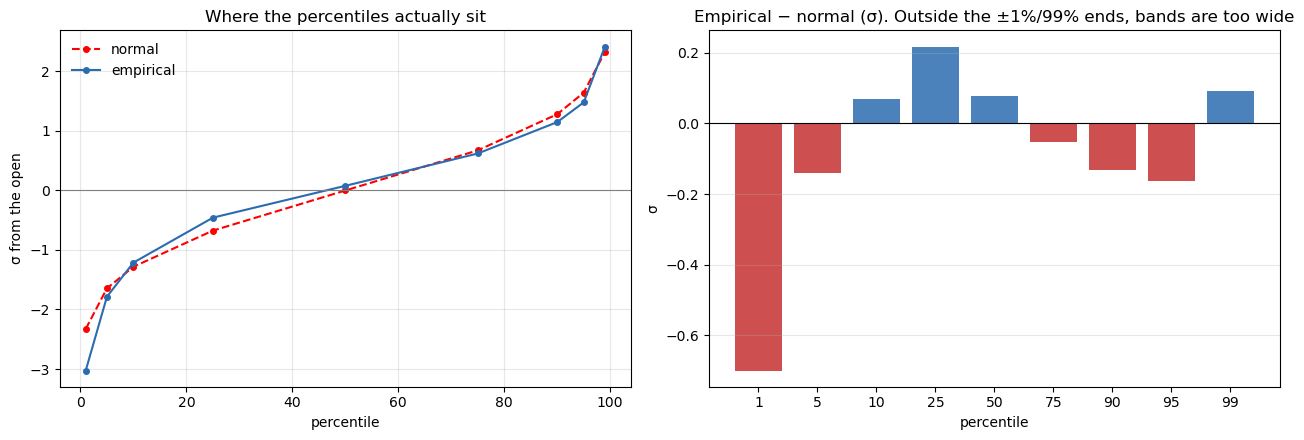

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
ax.plot(pct_rth.index, pct_rth["z_normal"], "r--", marker="o", ms=4, label="normal")
ax.plot(pct_rth.index, pct_rth["z_empirical"], color="#2b6cb0", marker="o", ms=4,
        label="empirical")
ax.axhline(0, color="grey", lw=0.8)
ax.set_title("Where the percentiles actually sit")
ax.set_xlabel("percentile"); ax.set_ylabel("σ from the open")
ax.grid(alpha=0.3); ax.legend(frameon=False)

ax = axes[1]
colors = ["#c53030" if v < 0 else "#2b6cb0" for v in pct_rth["diff"]]
ax.bar(range(len(pct_rth)), pct_rth["diff"], color=colors, alpha=0.85)
ax.set_xticks(range(len(pct_rth)))
ax.set_xticklabels([f"{int(p)}" for p in pct_rth.index])
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Empirical − normal (σ). Outside the ±1%/99% ends, bands are too wide")
ax.set_xlabel("percentile"); ax.set_ylabel("σ")
ax.grid(alpha=0.3, axis="y")

plt.tight_layout(); plt.show()

## 7. Extension from the open

The close-based numbers ignore everything that happened during the period. This
measures the excursions instead — how far price actually *travelled* from the open,
whether or not it stayed there.

* **up** — `(high − open) / open`, the maximum reach above the open
* **down** — `(open − low) / open`
* **range** — the full high-to-low span
* **|close|** — the absolute net move, shown for contrast

`mean_sd` / `median_sd` are the same quantities in σ units, so they're directly
comparable to the k values in the coverage table.

In [13]:
ext_rth = extension_table(rth)
ext_rth.round(3)

,mean_pct,median_pct,mean_sd,median_sd,p10_pct,p25_pct,p50_pct,p75_pct,p90_pct,p95_pct,p99_pct
up,0.658,0.479,0.687,0.519,0.082,0.214,0.479,0.904,1.431,1.821,2.941
down,0.717,0.477,0.757,0.506,0.074,0.204,0.477,0.995,1.662,2.197,3.451
range,1.374,1.157,1.444,1.245,0.560,0.791,1.157,1.686,2.435,3.041,4.612
|close|,0.714,0.507,0.748,0.546,0.079,0.218,0.507,0.995,1.582,2.067,3.273


In [14]:
es = extension_summary(rth)
print("RTH extension from the open")
print(f"  mean  up   {es['mean_up_pct']:6.3f}%     "
      f"mean  down {es['mean_down_pct']:6.3f}%")
print(f"  median up  {es['median_up_pct']:6.3f}%     "
      f"median down {es['median_down_pct']:6.3f}%")
print(f"  mean range {es['mean_range_pct']:6.3f}%     "
      f"median range {es['median_range_pct']:6.3f}%")
print()
print(f"  mean |close move|   {es['mean_abs_close_pct']:6.3f}%")
print(f"  close capture       {es['close_capture'] * 100:5.1f}%   "
      f"(share of the range still held at the close)")
print(f"  P(up reach > down reach)  {es['p_up_gt_down'] * 100:5.1f}%")
print()
print(f"  mean give-back from the high  {es['mean_giveback_from_high_pct']:6.3f}%")
print(f"  mean give-back from the low   {es['mean_giveback_from_low_pct']:6.3f}%")
print()
print(f"  median extension reached:  +{es['median_up_sd']:.2f} σ / "
      f"−{es['median_down_sd']:.2f} σ")
print("  -> the typical session tags roughly this band on each side before the close.")

RTH extension from the open
  mean  up    0.658%     mean  down  0.717%
  median up   0.479%     median down  0.477%
  mean range  1.374%     median range  1.157%

  mean |close move|    0.714%
  close capture        51.9%   (share of the range still held at the close)
  P(up reach > down reach)   50.0%

  mean give-back from the high   0.635%
  mean give-back from the low    0.740%

  median extension reached:  +0.52 σ / −0.51 σ
  -> the typical session tags roughly this band on each side before the close.


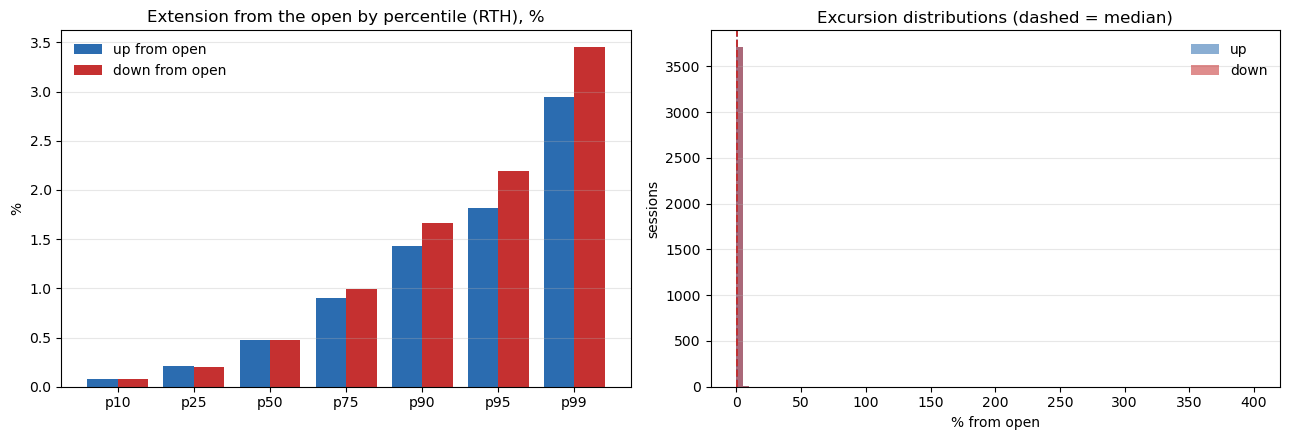

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
qs = [0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
labels = [f"p{int(q * 100)}" for q in qs]
up_q = [rth["up_exc"].quantile(q) * 100 for q in qs]
dn_q = [rth["dn_exc"].quantile(q) * 100 for q in qs]
x = np.arange(len(qs))
ax.bar(x - 0.2, up_q, 0.4, color="#2b6cb0", label="up from open")
ax.bar(x + 0.2, dn_q, 0.4, color="#c53030", label="down from open")
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_title("Extension from the open by percentile (RTH), %")
ax.set_ylabel("%"); ax.grid(alpha=0.3, axis="y"); ax.legend(frameon=False)

ax = axes[1]
ax.hist(rth["up_exc"] * 100, bins=80, range=(0, 400), alpha=0.55,
        color="#2b6cb0", label="up")
ax.hist(rth["dn_exc"] * 100, bins=80, range=(0, 400), alpha=0.55,
        color="#c53030", label="down")
ax.axvline(es["median_up_pct"], color="#2b6cb0", ls="--", lw=1.4)
ax.axvline(es["median_down_pct"], color="#c53030", ls="--", lw=1.4)
ax.set_title("Excursion distributions (dashed = median)")
ax.set_xlabel("% from open"); ax.set_ylabel("sessions")
ax.grid(alpha=0.3, axis="y"); ax.legend(frameon=False)

plt.tight_layout(); plt.show()

## 8. Diagnostic charts

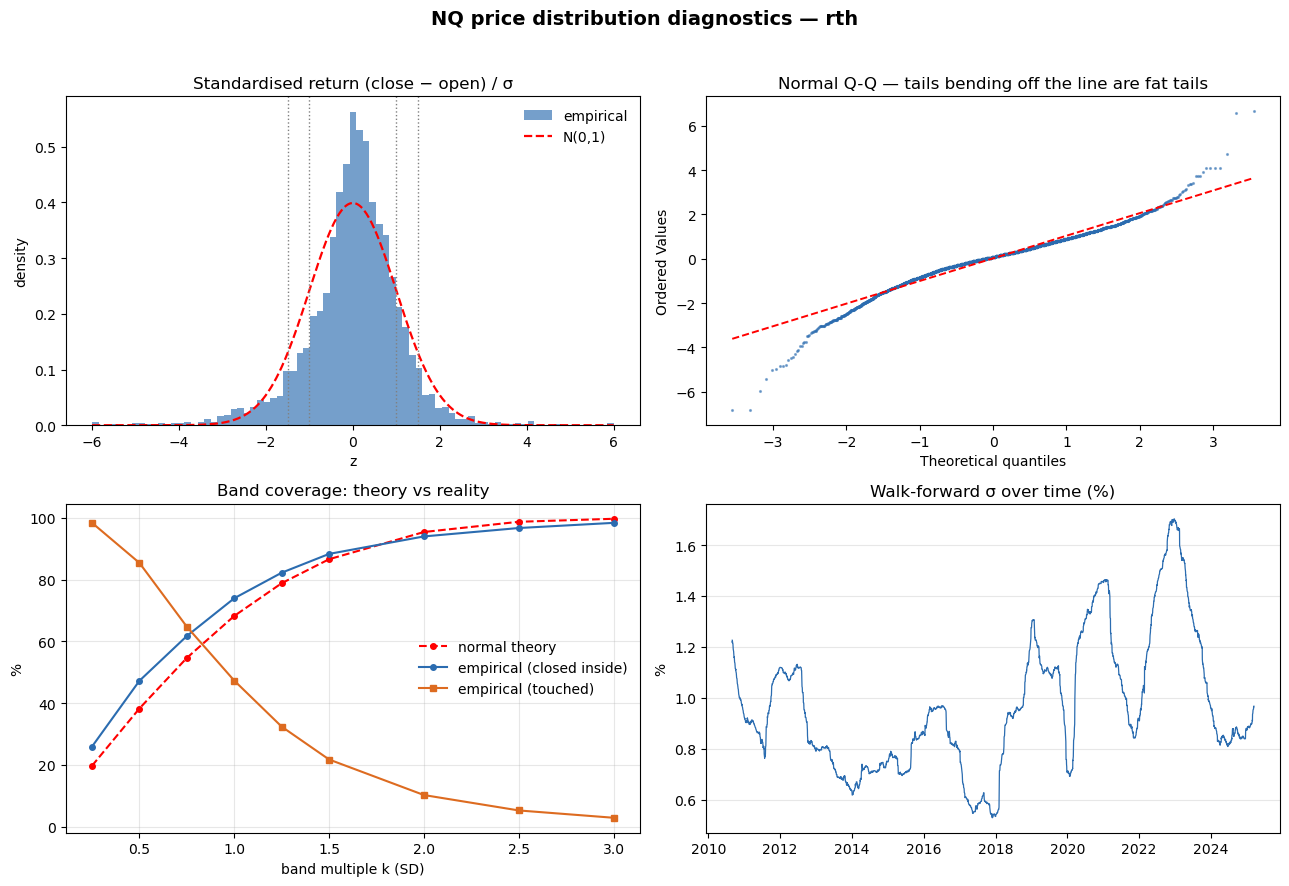

'dist_output\\dist_rth.png'

In [16]:
def make_charts(name, per, cov, prof):
    z = per["z"].dropna()
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    fig.suptitle(f"NQ price distribution diagnostics — {name}",
                 fontsize=14, fontweight="bold")

    ax = axes[0, 0]
    lim = float(min(6, max(4, np.ceil(z.abs().quantile(0.999)))))
    ax.hist(z.clip(-lim, lim), bins=np.linspace(-lim, lim, 80), density=True,
            alpha=0.65, color="#2b6cb0", label="empirical")
    xs = np.linspace(-lim, lim, 400)
    ax.plot(xs, stats.norm.pdf(xs), "r--", lw=1.6, label="N(0,1)")
    for k in (1.0, 1.5):
        ax.axvline(k, color="grey", ls=":", lw=1); ax.axvline(-k, color="grey", ls=":", lw=1)
    ax.set_title("Standardised return (close − open) / σ")
    ax.set_xlabel("z"); ax.set_ylabel("density"); ax.legend(frameon=False)

    ax = axes[0, 1]
    stats.probplot(z, dist="norm", plot=ax)
    ax.get_lines()[0].set(marker=".", markersize=2.5, color="#2b6cb0", alpha=0.5)
    ax.get_lines()[1].set(color="red", ls="--", lw=1.4)
    ax.set_title("Normal Q-Q — tails bending off the line are fat tails")

    ax = axes[1, 0]
    ax.plot(cov.index, cov["norm_within"] * 100, "r--", marker="o", ms=4,
            label="normal theory")
    ax.plot(cov.index, cov["close_within"] * 100, color="#2b6cb0", marker="o", ms=4,
            label="empirical (closed inside)")
    ax.plot(cov.index, cov["touch_either"] * 100, color="#dd6b20", marker="s", ms=4,
            label="empirical (touched)")
    ax.set_title("Band coverage: theory vs reality")
    ax.set_xlabel("band multiple k (SD)"); ax.set_ylabel("%")
    ax.grid(alpha=0.3); ax.legend(frameon=False)

    ax = axes[1, 1]
    if len(prof) > 1:
        ax.bar(range(len(prof)), prof["sigma_pct"], color="#2b6cb0", alpha=0.85)
        ax.set_xticks(range(len(prof)))
        ax.set_xticklabels(prof.index, rotation=90, fontsize=7)
        ax.set_title("σ by bucket (%)"); ax.set_ylabel("%")
    else:
        ax.plot(per.index, per["sigma"] * 100, color="#2b6cb0", lw=0.9)
        ax.set_title("Walk-forward σ over time (%)"); ax.set_ylabel("%")
    ax.grid(alpha=0.3, axis="y")

    fig.tight_layout(rect=(0, 0, 1, 0.96))
    path = os.path.join(OUTDIR, f"dist_{name.replace(':', '').replace('-', '_')}.png")
    fig.savefig(path, dpi=130)
    plt.show()
    return path


make_charts("rth", rth, cov_rth, sigma_profile(rth))

## 9. What happens after a band is tagged

The site describes outer-band extensions as "statistically stretched and often
watched for mean reversion". This quantifies that: given the +k band was reached
intraperiod, how often did price give it back?

`tag_rate` is per side, so it's roughly half the two-sided `touched either` above.

In [17]:
fade_rth = fade_table(rth)
disp = fade_rth.copy()
disp[["tag_rate", "p_close_inside", "p_fade_halfway", "p_fade_to_open"]] *= 100
disp = disp.round(1)
disp.columns = ["n tagged", "tag rate %", "closed back inside %",
                "faded halfway %", "faded through open %"]
disp

,n tagged,tag rate %,closed back inside %,faded halfway %,faded through open %
k,,,,,
0.25,5397,72.7,49.1,41.7,34.5
0.50,3763,50.7,48.0,32.7,22.2
0.75,2632,35.5,46.1,26.3,14.9
1.00,1861,25.1,48.1,21.7,10.6
1.25,1253,16.9,47.5,18.3,8.3
1.50,836,11.3,48.3,15.9,8.0
2.00,397,5.3,44.1,14.1,7.8
2.50,204,2.7,40.7,11.8,6.9
3.00,112,1.5,47.3,11.6,7.1


## 10. Path-dependent retracement

Section 9 asks where price *finished*. This asks what happened *along the way*.

For each level pair — P90→P75, P75→P50, P50→P25 — it finds the first bar that
tagged the upper threshold, then checks whether price traded back inside the lower
one before the period ended. A session can tag P90, collapse to P50 and rally back
to close at P85; the close-only view records that as "held", the path does not.

This is the one measurement the Pine indicator makes that the rest of this notebook
doesn't. Thresholds here are percentages of the open and shifted one period, so the
session is never scored against a sample containing itself.

In [18]:
rth_thr = add_excursion_thresholds(rth)
paths_rth = path_retrace(df, rth_thr, "rth")
retr_rth = retrace_table(paths_rth)

disp = retr_rth.copy()
disp[["p_retraced", "p_held_to_close"]] *= 100
disp = disp.round(1)
disp.columns = ["retraced to", "n tagged", "traded back inside %", "held to close %"]
print(f"Path statistics over {len(paths_rth):,} RTH sessions "
      f"(up and down sides pooled)\n")
disp

Path statistics over 3,711 RTH sessions (up and down sides pooled)



,retraced to,n tagged,traded back inside %,held to close %
level,,,,
P90,P75,789,37.1,51.0
P75,P50,1846,42.3,52.9
P50,P25,3655,59.2,51.8


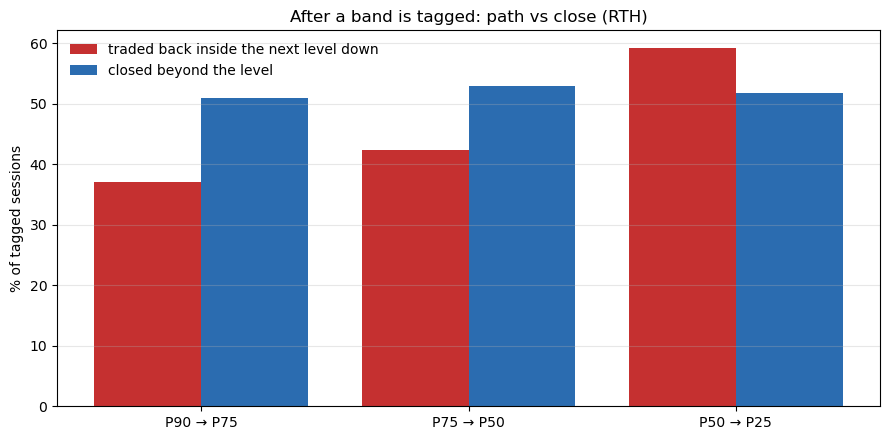

,traded back inside (path),still outside at close,closed beyond the level
level,,,
P90,37.1,62.9,51.0
P75,42.3,57.7,52.9
P50,59.2,40.8,51.8


In [19]:
# Path view vs close view, on the same tagged sessions.
comp_path = pd.DataFrame({
    "traded back inside (path)": retr_rth["p_retraced"] * 100,
    "still outside at close": (1 - retr_rth["p_retraced"]) * 100,
    "closed beyond the level": retr_rth["p_held_to_close"] * 100,
}).round(1)

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(retr_rth))
ax.bar(x - 0.2, retr_rth["p_retraced"] * 100, 0.4, color="#c53030",
       label="traded back inside the next level down")
ax.bar(x + 0.2, retr_rth["p_held_to_close"] * 100, 0.4, color="#2b6cb0",
       label="closed beyond the level")
ax.set_xticks(x)
ax.set_xticklabels([f"{i} → {r['retrace_to']}" for i, r in retr_rth.iterrows()])
ax.set_ylabel("% of tagged sessions"); ax.grid(alpha=0.3, axis="y")
ax.set_title("After a band is tagged: path vs close (RTH)")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

comp_path

## 11. σ across the clock

The single biggest reason to fit σ per bucket: hours are not interchangeable.

  period=hour          85,909 periods  (dropped 2,060 thin/weekend, min_bars=30)


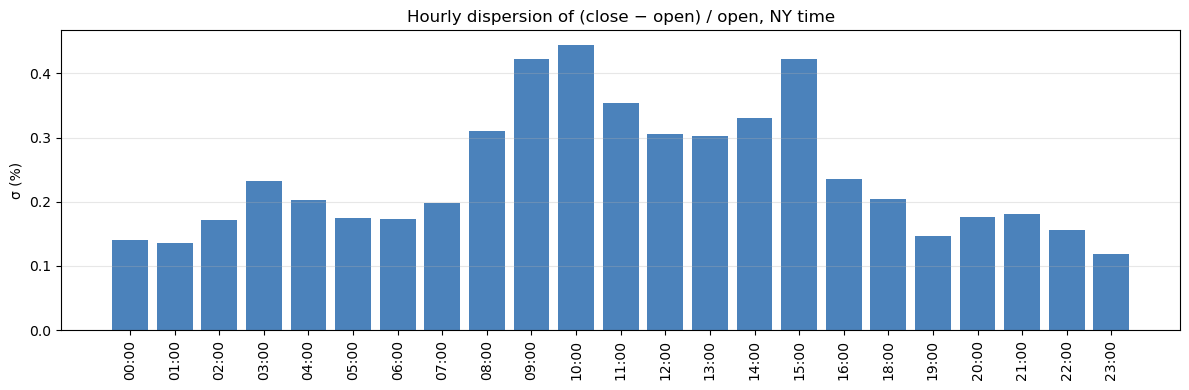

Loudest hour 10:00 at 0.445%; quietest 23:00 at 0.118% — a 3.8× spread.


,n,sigma_pct,mean_ret_pct,mean_range_pct,kurtosis,skew
bucket,,,,,,
00:00,3610,0.140,0.006,0.146,333.545,10.870
01:00,3656,0.136,0.004,0.170,27.911,-0.868
02:00,3715,0.171,0.011,0.218,18.109,1.393
03:00,3722,0.233,0.002,0.315,9.059,0.444
04:00,3722,0.203,0.002,0.270,10.624,-0.276
05:00,3723,0.175,0.003,0.236,10.484,-0.440
06:00,3729,0.173,0.003,0.228,48.110,-0.561
07:00,3735,0.199,0.001,0.252,14.904,-1.255
08:00,3734,0.311,0.002,0.349,53.576,1.172


In [20]:
hourly = add_zscores(add_sigma(add_returns(build_periods(df, "hour"))))
prof_hour = sigma_profile(hourly)

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(prof_hour.index, prof_hour["sigma_pct"], color="#2b6cb0", alpha=0.85)
ax.set_title("Hourly dispersion of (close − open) / open, NY time")
ax.set_ylabel("σ (%)"); ax.grid(alpha=0.3, axis="y")
plt.xticks(rotation=90); plt.tight_layout(); plt.show()

ratio = prof_hour["sigma_pct"].max() / prof_hour["sigma_pct"].min()
print(f"Loudest hour {prof_hour['sigma_pct'].idxmax()} at "
      f"{prof_hour['sigma_pct'].max():.3f}%; quietest "
      f"{prof_hour['sigma_pct'].idxmin()} at {prof_hour['sigma_pct'].min():.3f}% "
      f"— a {ratio:.1f}× spread.")
prof_hour.round(3)

### Median extension by hour

Same idea applied to the excursions: how far the typical hour reaches above and
below its own open, in basis points.

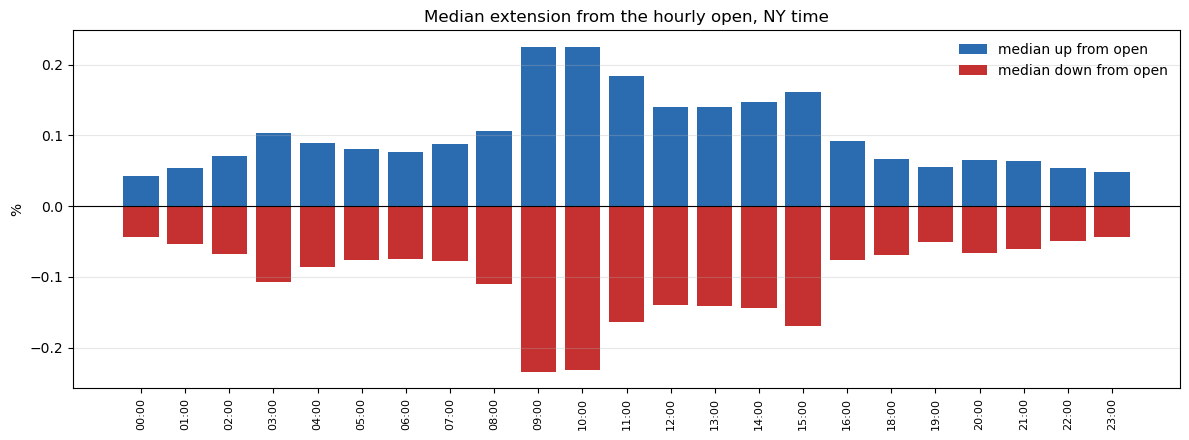

,med_up_pct,med_dn_pct,med_range_pct
bucket,,,
00:00,0.043,0.044,0.102
01:00,0.054,0.053,0.126
02:00,0.072,0.068,0.164
03:00,0.103,0.107,0.252
04:00,0.089,0.086,0.215
05:00,0.080,0.076,0.185
06:00,0.076,0.075,0.181
07:00,0.088,0.077,0.198
08:00,0.107,0.111,0.258


In [21]:
ext_hour = hourly.groupby("bucket").agg(
    med_up_pct=("up_exc", lambda s: s.median() * 100),
    med_dn_pct=("dn_exc", lambda s: s.median() * 100),
    med_range_pct=("range_pct", lambda s: s.median() * 100),
).sort_index()

fig, ax = plt.subplots(figsize=(12, 4.5))
x = np.arange(len(ext_hour))
ax.bar(x, ext_hour["med_up_pct"], color="#2b6cb0", label="median up from open")
ax.bar(x, -ext_hour["med_dn_pct"], color="#c53030", label="median down from open")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(ext_hour.index, rotation=90, fontsize=8)
ax.set_title("Median extension from the hourly open, NY time")
ax.set_ylabel("%"); ax.grid(alpha=0.3, axis="y"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

ext_hour.round(3)

## 12. Live expected-range map

Feed in the open of the period you're trading and the latest σ. The empirical
columns are the ones to trust where they disagree with the normal ones.

In [22]:
open_price = float(rth["Close"].iloc[-1])       # substitute today's actual open
sigma_now  = float(rth["sigma"].dropna().iloc[-1])

rmap = expected_range_map(open_price, sigma_now, empirical=cov_rth)
print(f"RTH open {open_price:,.2f}   σ = {sigma_now * 100:.3f}% "
      f"= {sigma_now * open_price:,.1f} pts per 1 SD\n")

show = rmap[["lower", "upper", "width_pts", "emp_within", "emp_touch_either",
             "norm_within"]].copy()
show[["emp_within", "emp_touch_either", "norm_within"]] *= 100
show.columns = ["lower", "upper", "width (pts)", "P(close inside) %",
                "P(touch) %", "normal theory %"]
show.round(2)

RTH open 19,705.25   σ = 0.967% = 190.5 pts per 1 SD



,lower,upper,width (pts),P(close inside) %,P(touch) %,normal theory %
k,,,,,,
0.25,19657.62,19752.88,95.27,25.95,98.44,19.74
0.50,19609.98,19800.52,190.53,47.26,85.45,38.29
0.75,19562.35,19848.15,285.80,61.76,64.78,54.67
1.00,19514.72,19895.78,381.07,74.00,47.32,68.27
1.25,19467.08,19943.42,476.34,82.27,32.42,78.87
1.50,19419.45,19991.05,571.60,88.36,21.77,86.64
2.00,19324.18,20086.32,762.14,94.02,10.27,95.45
2.50,19228.91,20181.59,952.67,96.74,5.28,98.76
3.00,19133.65,20276.85,1143.21,98.41,2.91,99.73


### Percentile levels — the non-parametric version

Same σ, but the shape comes from the observed distribution instead of the normal
curve. `gap_pts` is how far the textbook model misplaces each level.

In [23]:
pmap = percentile_range_map(rth, open_price, sigma_now)
pmap.round(2)

,empirical,normal,gap_pts
pct,,,
1.0,19128.78,19262.00,-133.22
5.0,19365.10,19391.85,-26.75
10.0,19474.29,19461.07,13.22
25.0,19618.23,19576.74,41.50
50.0,19720.19,19705.25,14.94
75.0,19823.69,19833.76,-10.07
90.0,19924.23,19949.43,-25.20
95.0,19987.37,20018.65,-31.28
99.0,20166.19,20148.50,17.69


### Extension targets

Where price is likely to *reach* during the period, as opposed to where it closes.
The median row is the one to anchor on; p90 and above are stretch scenarios.

In [24]:
etarg = extension_targets(rth, open_price, sigma_now)
etarg.round(2)

,up,down,up_pts,down_pts
stat,,,,
mean,19836.10,19561.00,130.85,144.25
median,19804.13,19608.88,98.88,96.37
p10,19721.85,19689.51,16.60,15.74
p25,19749.74,19662.74,44.49,42.51
p50,19804.13,19608.88,98.88,96.37
p75,19888.41,19507.27,183.16,197.98
p90,19985.43,19373.65,280.18,331.60
p95,20054.10,19270.11,348.85,435.14
p99,20232.61,19006.43,527.36,698.82


## 13. Batch run — every period type, with CSV export

In [25]:
results = {}
for period in PERIODS:
    per = add_zscores(add_sigma(add_returns(build_periods(df, period))))
    if len(per) < 50:
        print(f"  !! {period}: only {len(per)} usable periods, skipping")
        continue
    cov, fade, prof = coverage_table(per), fade_table(per), sigma_profile(per)
    pct, ext = percentile_table(per), extension_table(per)
    summ, esumm = distribution_summary(per), extension_summary(per)
    results[period] = {"periods": per, "coverage": cov, "fade": fade,
                       "profile": prof, "percentiles": pct, "extension": ext,
                       "summary": summ, "ext_summary": esumm}

    tag = period.replace(":", "").replace("-", "_")
    per.to_csv(f"{OUTDIR}/periods_{tag}.csv")
    cov.to_csv(f"{OUTDIR}/coverage_{tag}.csv")
    fade.to_csv(f"{OUTDIR}/fade_{tag}.csv")
    prof.to_csv(f"{OUTDIR}/sigma_profile_{tag}.csv")
    pct.to_csv(f"{OUTDIR}/percentiles_{tag}.csv")
    ext.to_csv(f"{OUTDIR}/extension_{tag}.csv")

print(f"\nCSVs written to {os.path.abspath(OUTDIR)}/")

  period=rth            3,771 periods  (dropped 18 thin/weekend, min_bars=195)
  period=day            3,786 periods  (dropped 16 thin/weekend, min_bars=676)
  period=week             770 periods  (dropped 1 thin/weekend, min_bars=3316)
  period=hour          85,909 periods  (dropped 2,060 thin/weekend, min_bars=30)
  period=asia           3,771 periods  (dropped 24 thin/weekend, min_bars=266)
  period=london         3,791 periods  (dropped 7 thin/weekend, min_bars=195)

CSVs written to C:\Users\tammm\NQ and ES analysis\dist_output/


In [26]:
# Side-by-side comparison across period types.
comp = pd.DataFrame({
    p: {
        "n": r["summary"]["n"],
        "std z": round(r["summary"]["std_z"], 3),
        "skew": round(r["summary"]["skew"], 2),
        "excess kurt": round(r["summary"]["excess_kurtosis"], 2),
        "±0.5 SD actual": round(r["coverage"].loc[0.5, "close_within"] * 100, 1),
        "±1.0 SD actual": round(r["coverage"].loc[1.0, "close_within"] * 100, 1),
        "±1.5 SD actual": round(r["coverage"].loc[1.5, "close_within"] * 100, 1),
        "±2.0 SD actual": round(r["coverage"].loc[2.0, "close_within"] * 100, 1),
        "touch ±1 SD": round(r["coverage"].loc[1.0, "touch_either"] * 100, 1),
        "fade back in @1 SD": round(r["fade"].loc[1.0, "p_close_inside"] * 100, 1),
    } for p, r in results.items()
}).T
print("Site quotes: ±0.5 SD 38%,  ±1.0 SD 68%,  ±1.5 SD 87%  (normal theory)\n")
comp

Site quotes: ±0.5 SD 38%,  ±1.0 SD 68%,  ±1.5 SD 87%  (normal theory)



,n,std z,skew,excess kurt,±0.5 SD actual,±1.0 SD actual,±1.5 SD actual,±2.0 SD actual,touch ±1 SD,fade back in @1 SD
rth,3711.0,1.046,-0.57,4.10,47.3,74.0,88.4,94.0,47.3,48.1
day,3726.0,1.043,-0.37,4.03,47.7,73.5,86.9,94.0,45.4,44.9
week,710.0,1.027,-0.42,2.81,42.1,71.5,89.0,94.8,49.7,45.7
hour,84503.0,1.098,-0.01,56.36,53.2,79.1,89.8,94.6,40.4,51.7
asia,3711.0,1.098,-0.64,16.11,53.5,78.7,89.0,94.0,40.5,51.3
london,3731.0,1.041,-0.15,4.72,49.3,76.3,88.6,94.2,45.8,51.6


### Percentiles and extension, side by side

`p5` / `p95` are the empirical σ levels; the normal model puts them at ∓1.645.
`med up` / `med down` are the median excursions, also in σ.

In [27]:
comp2 = pd.DataFrame({
    p: {
        "p1 (σ)": round(r["percentiles"].loc[1.0, "z_empirical"], 2),
        "p5 (σ)": round(r["percentiles"].loc[5.0, "z_empirical"], 2),
        "p25 (σ)": round(r["percentiles"].loc[25.0, "z_empirical"], 2),
        "p50 (σ)": round(r["percentiles"].loc[50.0, "z_empirical"], 2),
        "p75 (σ)": round(r["percentiles"].loc[75.0, "z_empirical"], 2),
        "p95 (σ)": round(r["percentiles"].loc[95.0, "z_empirical"], 2),
        "p99 (σ)": round(r["percentiles"].loc[99.0, "z_empirical"], 2),
        "med up (σ)": round(r["ext_summary"]["median_up_sd"], 2),
        "med down (σ)": round(r["ext_summary"]["median_down_sd"], 2),
        "med range %": round(r["ext_summary"]["median_range_pct"], 1),
        "close capture %": round(r["ext_summary"]["close_capture"] * 100, 1),
    } for p, r in results.items()
}).T
print("Normal model: p1 −2.33,  p5 −1.64,  p25 −0.67,  p75 +0.67,  "
      "p95 +1.64,  p99 +2.33\n")
comp2

Normal model: p1 −2.33,  p5 −1.64,  p25 −0.67,  p75 +0.67,  p95 +1.64,  p99 +2.33



,p1 (σ),p5 (σ),p25 (σ),p50 (σ),p75 (σ),p95 (σ),p99 (σ),med up (σ),med down (σ),med range %,close capture %
rth,-3.03,-1.79,-0.46,0.08,0.62,1.48,2.42,0.52,0.51,1.2,51.9
day,-3.00,-1.71,-0.41,0.10,0.64,1.63,2.60,0.55,0.49,1.4,51.4
week,-2.74,-1.45,-0.41,0.17,0.73,1.72,2.64,0.62,0.52,3.4,51.2
hour,-3.08,-1.55,-0.42,0.04,0.49,1.49,2.87,0.48,0.46,0.2,49.3
asia,-3.08,-1.49,-0.37,0.09,0.54,1.65,3.31,0.50,0.44,0.4,49.4
london,-3.16,-1.66,-0.45,0.04,0.57,1.56,2.72,0.55,0.51,0.6,48.4


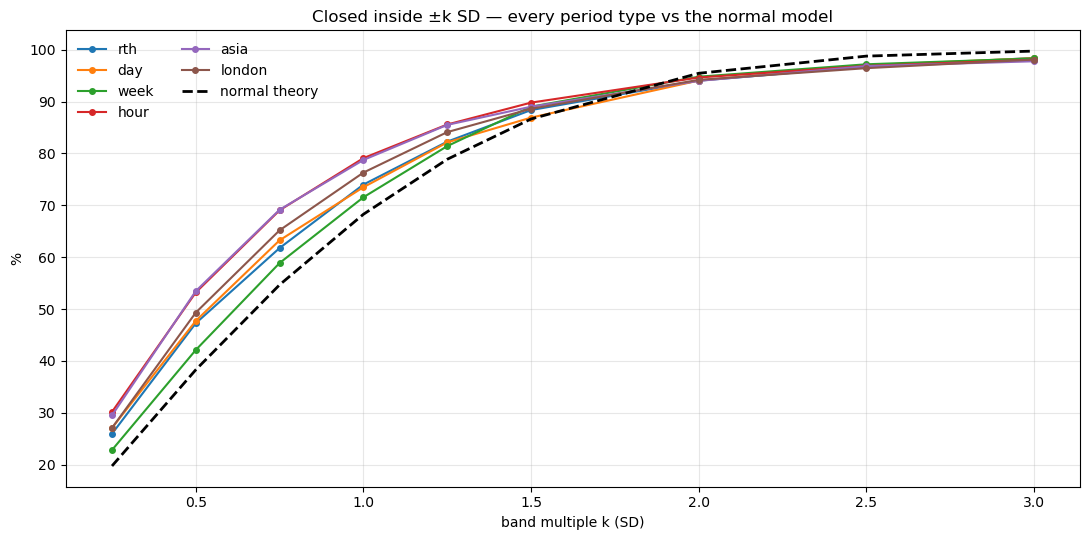

In [28]:
# Coverage curves, all period types on one axis.
fig, ax = plt.subplots(figsize=(11, 5.5))
for p, r in results.items():
    ax.plot(r["coverage"].index, r["coverage"]["close_within"] * 100,
            marker="o", ms=4, label=p)
ax.plot(cov_rth.index, cov_rth["norm_within"] * 100, "k--", lw=2, label="normal theory")
ax.set_title("Closed inside ±k SD — every period type vs the normal model")
ax.set_xlabel("band multiple k (SD)"); ax.set_ylabel("%")
ax.grid(alpha=0.3); ax.legend(frameon=False, ncol=2)
plt.tight_layout(); plt.show()

## 14. Sigma model comparison

A well-calibrated σ gives `std z` near 1.0. Well above means σ is running too
small (the window is too long to track vol regime changes); well below means it's
too large. `full` uses one in-sample number for the whole history, which is what a
literal reading of the site's method gives you — note that it sees the future.

In [29]:
base = add_returns(build_periods(df, "rth", verbose=False))
rows = []
for name, kw in {
    "rolling-60":  dict(method="rolling", window=60),
    "rolling-252": dict(method="rolling", window=252),
    "rolling-504": dict(method="rolling", window=504),
    "ewma-hl40":   dict(method="ewma", halflife=40),
    "expanding":   dict(method="expanding"),
    "full (peeks)": dict(method="full"),
}.items():
    p = add_zscores(add_sigma(base, **kw))
    s, c = distribution_summary(p), coverage_table(p)
    rows.append({"model": name, "n": s["n"], "std z": round(s["std_z"], 3),
                 "excess kurt": round(s["excess_kurtosis"], 2),
                 "±1 SD %": round(c.loc[1.0, "close_within"] * 100, 1),
                 "±1.5 SD %": round(c.loc[1.5, "close_within"] * 100, 1),
                 "±2 SD %": round(c.loc[2.0, "close_within"] * 100, 1)})
pd.DataFrame(rows).set_index("model")

,n,std z,excess kurt,±1 SD %,±1.5 SD %,±2 SD %
model,,,,,,
rolling-60,3711,1.069,2.54,72.1,86.4,93.7
rolling-252,3711,1.046,4.10,74.0,88.4,94.0
rolling-504,3711,1.027,3.98,74.9,88.5,94.1
ewma-hl40,3711,1.018,2.50,73.2,87.9,94.6
expanding,3711,1.085,3.65,72.3,86.7,93.1
full (peeks),3771,1.000,3.28,75.2,88.5,94.5


## 15. Export levels back to the Pine indicator

The indicator stores its levels in points, which cannot travel across price
regimes or instruments. These are the same levels as percentages of the session
open, measured over the full history rather than a trailing 100 sessions.

Windows here match the indicator's own — note its NY morning opens at 08:00
pre-market, not at the 09:30 RTH open, so these differ from the `nyam` figures
elsewhere in this notebook.

In [30]:
PINE_SESSIONS = ["pine_asia", "pine_london", "pine_nyam", "pine_nypm"]

plev = pine_levels(df, PINE_SESSIONS)
plev.to_csv(f"{OUTDIR}/pine_levels_pct.csv")
plev.round(3)

,n,mfe_p25,mae_p25,rng_p25,mfe_p50,mae_p50,rng_p50,mfe_p75,mae_p75,rng_p75,mfe_p90,mae_p90,rng_p90,mfe_mean,mae_mean
session,,,,,,,,,,,,,,,
pine_asia,3764,0.073,0.058,0.239,0.163,0.140,0.366,0.314,0.294,0.573,0.539,0.533,0.908,0.247,0.241
pine_london,3783,0.103,0.090,0.340,0.221,0.204,0.502,0.406,0.409,0.776,0.691,0.735,1.139,0.315,0.315
pine_nyam,3789,0.179,0.181,0.652,0.390,0.413,0.948,0.719,0.804,1.394,1.156,1.323,1.908,0.528,0.582
pine_nypm,3673,0.162,0.128,0.525,0.336,0.315,0.771,0.611,0.653,1.185,1.014,1.153,1.769,0.471,0.504


In [31]:
span = f", {df.index[0]:%Y-%m-%d} to {df.index[-1]:%Y-%m-%d}"
snippet = pine_snippet(plev, span=span)

with open(f"{OUTDIR}/pine_levels.txt", "w", encoding="utf-8") as fh:
    fh.write(snippet)

print(snippet)

// --- Empirical excursion levels, % of session open ---
// Generated from NQ 1-minute data, 2010-06-06 to 2025-03-14.
// Index: 0=P25  1=P50  2=P75  3=P90

var float[] ASIA_MFE = array.from(0.073, 0.163, 0.314, 0.539)   // n=3764
var float[] ASIA_MAE = array.from(0.058, 0.140, 0.294, 0.533)
var float[] LON_MFE = array.from(0.103, 0.221, 0.406, 0.691)   // n=3783
var float[] LON_MAE = array.from(0.090, 0.204, 0.409, 0.735)
var float[] NYAM_MFE = array.from(0.179, 0.390, 0.719, 1.156)   // n=3789
var float[] NYAM_MAE = array.from(0.181, 0.413, 0.804, 1.323)
var float[] NYPM_MFE = array.from(0.162, 0.336, 0.611, 1.014)   // n=3673
var float[] NYPM_MAE = array.from(0.128, 0.315, 0.653, 1.153)

// Convert a stored percentage into a price level for the live session.
f_up_level(s_open, pctArr, i) => s_open * (1 + array.get(pctArr, i) / 100)
f_dn_level(s_open, pctArr, i) => s_open * (1 - array.get(pctArr, i) / 100)

// e.g. the P75 upside band for NY morning:
//   lvl = f_up_level(nyam_o, NYA

To use these in the indicator, replace the rolling `f_pct_val(mfe_a, p)` calls with
`f_up_level(s_open, NYAM_MFE, i)` and the MAE equivalents. That swaps a 100-session
points-based estimate for a 15-year percentage-based one — more stable and portable
to ES, at the cost of no longer adapting to the current volatility regime.

If you want both, scale the fixed percentages by the ratio of recent realised σ to
its long-run average, which is what section 3 does here.

## Reading the output

**The site's percentages are theory, not measurement.** 38 / 68 / 87 and the
one-sided 69 / 84 / 93 are `2Φ(k) − 1` and `Φ(k)` evaluated at 0.5, 1.0 and 1.5.
The tables above put your measured rates next to them.

**Expect a crossover.** Equity index returns are leptokurtic — more mass at the
centre, thinner shoulders, fatter tails. So the inner bands hold *better* than
theory and the outer bands break *more* often. The k where `within_edge` turns
negative is the point past which the normal model starts underestimating risk.

**Touch ≫ close.** The site's figures are close-based. If you're placing orders at
a band, `touch_either` is the number that matters, and it's much larger.

**Percentiles beat k·σ where the two disagree.** Section 6 reads the levels straight
off the observed distribution — no normality assumption. The mid-distribution
quantiles land tighter than the normal model says while the 1st and 99th land wider.
Use `percentile_range_map` when you want levels rather than probabilities.

**Extension answers a different question from the close.** Section 7 measures how
far price *reached*, not where it finished. `close_capture` is the give-away: the
gap between the mean absolute close move and the mean range is the round-trip that
a close-only study never sees. Median extension in σ tells you which band the
typical period tags before reverting.

**σ choice moves everything.** Compare the models in section 14 before settling.
Shorter windows adapt faster to vol regime shifts but add estimation noise.

**Where to take it next.** Condition on the prior period's outcome (does a wide
day beget a wide day), split by day-of-week, add a vol-regime filter using the
opening range, or check whether the fade rates in sections 9 and 10 survive transaction
costs before treating them as a strategy.